In [2]:
import pandas as pd
import glob
import numpy as np
from read_Loeb05_ADM import Loeb05_ADM
import matplotlib.pyplot as plt

In [3]:
ADM=Loeb05_ADM()
ADM.interpolate_ADM([45.0],[8.0],[44.0])

In [4]:
print(ADM.sza.shape,ADM.vza.shape,ADM.azi.shape,ADM.ADM.shape)

(9,) (9,) (10,) (9, 9, 10)


array([0.9216])

In [15]:
ADM.ADM[i,:,:].max()

1.1516

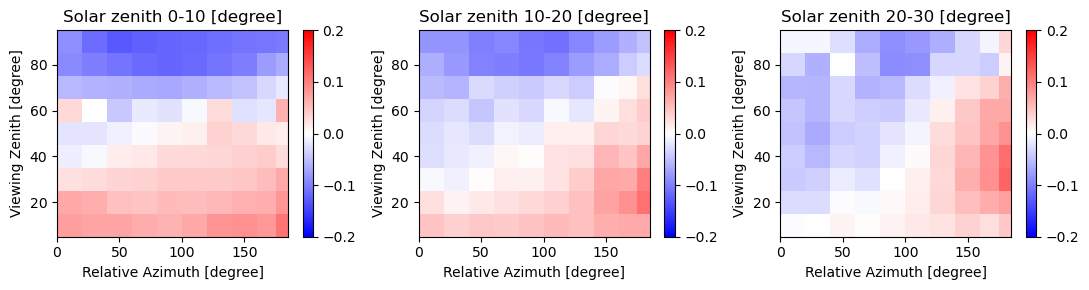

In [18]:
fig,ax=plt.subplots(1,3,figsize=[11,3],tight_layout=True)
i=0
sza_string=['0-10 [degree]','10-20 [degree]','20-30 [degree]']
for axis in ax:
    cf=axis.pcolormesh(ADM.azi,ADM.vza,ADM.ADM[i,:,:]-1,vmin=-0.2,vmax=.2,cmap='bwr')
    axis.set_xlabel('Relative Azimuth [degree]')
    axis.set_ylabel('Viewing Zenith [degree]')
    plt.colorbar(cf,ax=axis)
    axis.set_title('Solar zenith '+sza_string[i])
    i+=1
fig.savefig('ADM_anormally.png',dpi=300)

(0.9, 1.2)

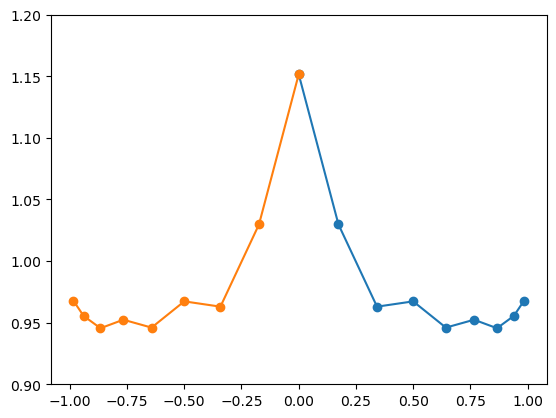

In [52]:
fig,ax=plt.subplots()
ax.plot(np.cos(np.radians(ADM.vza)),ADM.ADM[3,:,0],marker='o')
ax.plot(-np.cos(np.radians(ADM.vza)),ADM.ADM[3,:,0],marker='o')
ax.set_ylim([0.9,1.2])

(0.9, 1.2)

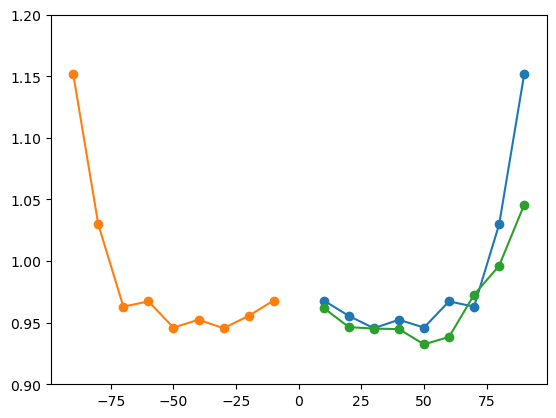

In [59]:
fig,ax=plt.subplots()
ax.plot(ADM.vza,ADM.ADM[3,:,0],marker='o')
ax.plot(-ADM.vza,ADM.ADM[3,:,0],marker='o')
ax.plot(ADM.vza,ADM.ADM[3,:,2],marker='o')
ax.set_ylim([0.9,1.2])

In [55]:
np.cos(np.radians(ADM.vza))
print(ADM.vza)

[10 20 30 40 50 60 70 80 90]


(9, 10) (9, 10)
[[0.17453293 0.52359878 0.87266463 1.22173048 1.57079633 1.91986218
  2.26892803 2.61799388 2.96705973 3.14159265]
 [0.17453293 0.52359878 0.87266463 1.22173048 1.57079633 1.91986218
  2.26892803 2.61799388 2.96705973 3.14159265]
 [0.17453293 0.52359878 0.87266463 1.22173048 1.57079633 1.91986218
  2.26892803 2.61799388 2.96705973 3.14159265]
 [0.17453293 0.52359878 0.87266463 1.22173048 1.57079633 1.91986218
  2.26892803 2.61799388 2.96705973 3.14159265]
 [0.17453293 0.52359878 0.87266463 1.22173048 1.57079633 1.91986218
  2.26892803 2.61799388 2.96705973 3.14159265]
 [0.17453293 0.52359878 0.87266463 1.22173048 1.57079633 1.91986218
  2.26892803 2.61799388 2.96705973 3.14159265]
 [0.17453293 0.52359878 0.87266463 1.22173048 1.57079633 1.91986218
  2.26892803 2.61799388 2.96705973 3.14159265]
 [0.17453293 0.52359878 0.87266463 1.22173048 1.57079633 1.91986218
  2.26892803 2.61799388 2.96705973 3.14159265]
 [0.17453293 0.52359878 0.87266463 1.22173048 1.57079633 1.91986

posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


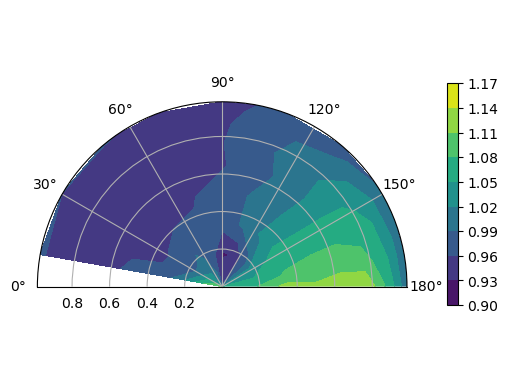

In [46]:
r, theta = np.meshgrid(np.radians(ADM.azi), np.cos(np.radians(ADM.vza)))
print(r.shape,theta.shape)
print(r)
print(theta)
# [r, th] = np.meshgrid(np.radians(ADM.azi),ADM.sza)
# print(r.shape,th.shape)

fig = plt.figure()
ax = fig.add_subplot(111, polar=True)
ax.set_theta_zero_location('W')
ax.set_theta_direction(-1)

cntf = ax.contourf(r,theta,ADM.ADM[3,:,:])
ax.set_thetamin(0)
ax.set_thetamax(180)
plt.colorbar(cntf, shrink=.6, pad=0.08)
# # ax.set_rlim(0, .3)
# # label_position=ax.get_rlabel_position()
# # ax.text(np.radians(label_position+25),ax.get_rmax()/1.5,'f (Hz)',
# #         rotation=label_position,ha='center',va='center')